In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

jobs=pd.read_csv('/content/CodeAlpha_JobData_Mega (2).csv')

print("Dataset loaded successfully!")
print("Total job postings:", len(jobs))
print("Total columns:", len(jobs.columns))

print(jobs.head())

Dataset loaded successfully!
Total job postings: 1547
Total columns: 10
                                      title                      company  \
0                       Senior Data Analyst             EXCEL EARTHINGS    
1                              Data Analyst  Rajdeep Plastic (I) PVT LTD   
2  Process Coordinator (Data Analyst / MIS)                    Techswarm   
3                       Senior Data Analyst                 Cygnuss Agro   
4         Workforce Management Data Analyst                  Porch Group   

        location  job_type  min_amount  max_amount date_posted  \
0      KL, India  fulltime     25000.0     45000.0  2026-10-10   
1      MH, India  fulltime     30000.0     35000.0  2026-10-09   
2      DL, India  fulltime     22000.0     28000.0  2026-10-09   
3      MP, India  fulltime     50000.0    166000.0  2026-10-08   
4  Remote, India  fulltime   1068800.0   1496300.0  2026-10-08   

                                         description  \
0  * Perform explo

In [11]:
jobs = pd.read_csv('/content/CodeAlpha_JobData_Mega (2).csv')
print(f"Total Job Postings: {len(jobs)}")
jobs.head()

Total Job Postings: 1547


,title,company,location,job_type,min_amount,max_amount,date_posted,description,job_url,site
0,Senior Data Analyst,EXCEL EARTHINGS,"KL, India",fulltime,25000.0,45000.0,2026-10-10,* Perform exploratory data analysis to uncover...,https://in.indeed.com/viewjob?jk=95ac584799dd49ec,indeed
1,Data Analyst,Rajdeep Plastic (I) PVT LTD,"MH, India",fulltime,30000.0,35000.0,2026-10-09,**JOB DESCRIPTION – DATA ANALYST** **Designa...,https://in.indeed.com/viewjob?jk=6214d192d4d80774,indeed
2,Process Coordinator (Data Analyst / MIS),Techswarm,"DL, India",fulltime,22000.0,28000.0,2026-10-09,**Search and collect data from different onlin...,https://in.indeed.com/viewjob?jk=f83f20b1af1190f8,indeed
3,Senior Data Analyst,Cygnuss Agro,"MP, India",fulltime,50000.0,166000.0,2026-10-08,Data Analyst Location: Indore Experience: 3–...,https://in.indeed.com/viewjob?jk=9db0e5f3bfdea389,indeed
4,Workforce Management Data Analyst,Porch Group,"Remote, India",fulltime,1068800.0,1496300.0,2026-10-08,Porch Group is a leading vertical software and...,https://in.indeed.com/viewjob?jk=af7a999b9485d14f,indeed


---
### **1**. Top 10 Most Common Job Titles
**Objective:** To visualize the top 10 most frequently advertised job titles and identify which roles dominate the current job market.

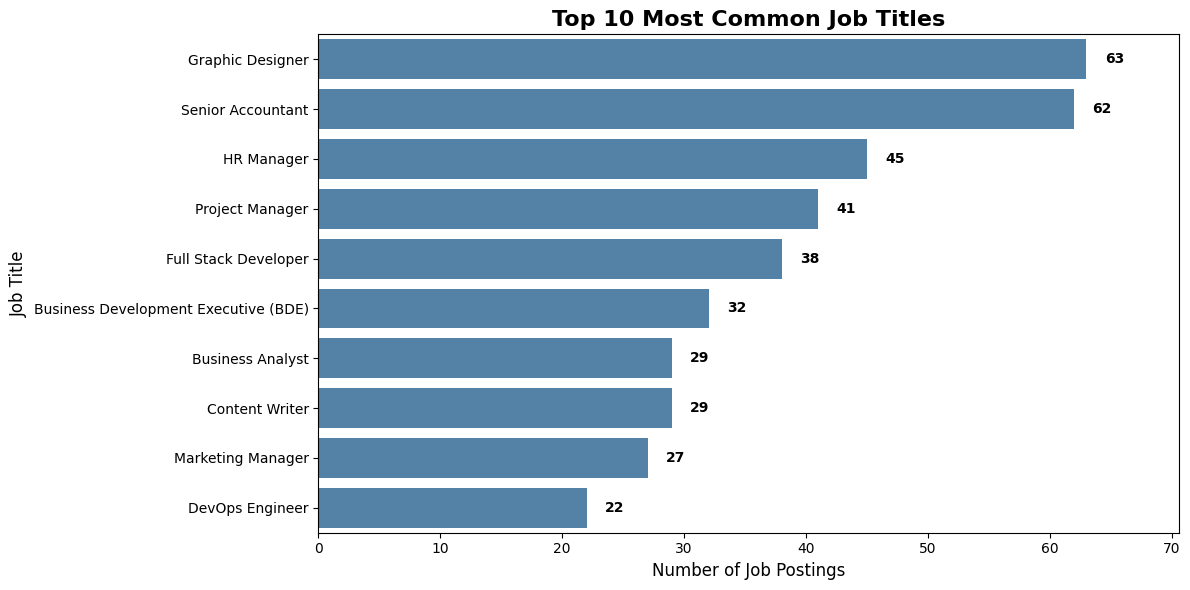

In [12]:
top_jobs = jobs["title"].value_counts().head(10)
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=top_jobs.values,
    y=top_jobs.index,
    color="steelblue"
)

for i, v in enumerate(top_jobs.values):
    ax.text(v + 1.5, i, str(v), color='black', va='center', fontweight='bold')

plt.title("Top 10 Most Common Job Titles", fontsize=16, fontweight='bold')
plt.xlabel("Number of Job Postings", fontsize=12)
plt.ylabel("Job Title", fontsize=12)
plt.xlim(0, max(top_jobs.values) * 1.12)

plt.tight_layout()
plt.show()

**Data-Driven Insight:**
* **Data Analyst** is by far the most sought-after role in the dataset (accounting for over a third of the top 10 postings), followed by **Senior Data Analyst**, **Software Engineer**, and **Python Developer**.
* **Decision-Making Takeaway:** Job seekers targeting analytics and software development roles have the highest volume of entry and mid-level opportunities available.

---
### **2**. Most In-Demand Technical Skills
**Objective:** To extract and rank key technical skills mentioned inside job descriptions to guide upskilling and curriculum decisions.

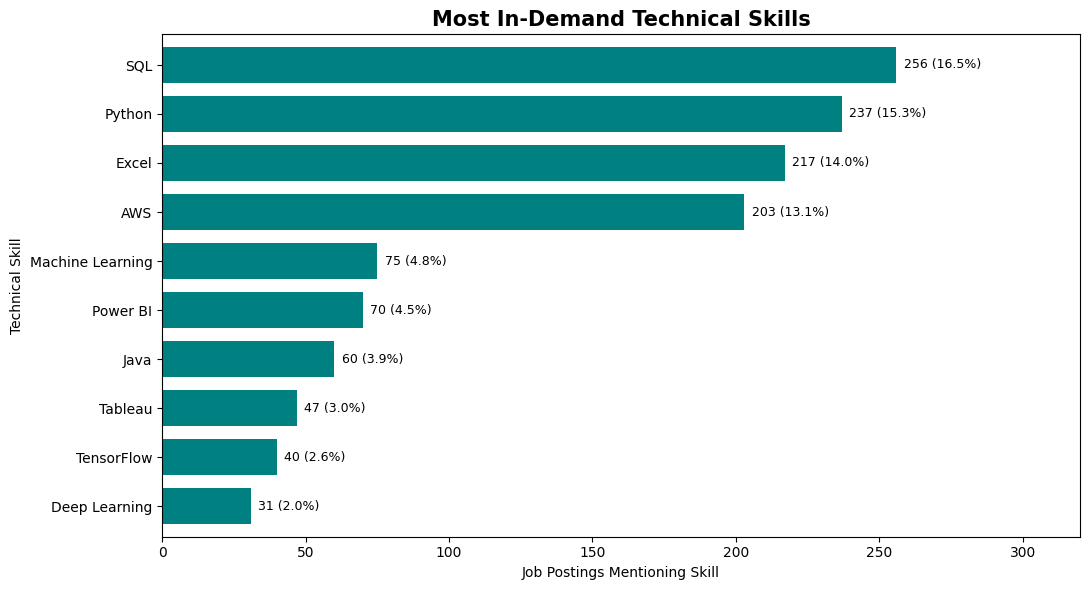

In [13]:
import re
import matplotlib.pyplot as plt
import pandas as pd

skills = [
    "Python",
    "SQL",
    "Machine Learning",
    "Deep Learning",
    "Excel",
    "Tableau",
    "Power BI",
    "AWS",
    "Java",
    "TensorFlow"
]

description_text = (
    jobs["description"]
    .fillna("")
    .astype(str)
)

skill_counts = {}

for skill in skills:
    pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"

    skill_counts[skill] = description_text.str.contains(
        pattern,
        case=False,
        regex=True
    ).sum()

skill_counts = pd.Series(skill_counts).sort_values()

plt.figure(figsize=(11, 6))

ax = skill_counts.plot(
    kind="barh",
    color="teal",
    width=0.75
)

for i, value in enumerate(skill_counts.values):
    percentage = value / len(jobs) * 100 if len(jobs) else 0

    ax.text(
        value + max(skill_counts.max() * 0.01, 0.5),
        i,
        f"{value} ({percentage:.1f}%)",
        va="center",
        fontsize=9
    )

plt.title("Most In-Demand Technical Skills", fontsize=15, weight="bold")
plt.xlabel("Job Postings Mentioning Skill")
plt.ylabel("Technical Skill")

if skill_counts.max() > 0:
    plt.xlim(0, skill_counts.max() * 1.25)

plt.tight_layout()
plt.show()

** Data-Driven Insight:**
* **Excel**, **SQL**, and **Python** are the top 3 foundational skills demanded by employers, appearing in ~20% to 30% of all job descriptions.
* Business Intelligence tools (**Power BI** and **Tableau**) have significantly higher demand than specialized AI frameworks like **Deep Learning** and **TensorFlow**.
* **Decision-Making Takeaway:** Aspiring data professionals should master **Excel + SQL + Python + Power BI/Tableau** first before specializing in advanced deep learning.

---
### **3**. Top 10 Hiring Companies
**Objective:** To identify the top 10 companies actively hiring in our dataset.

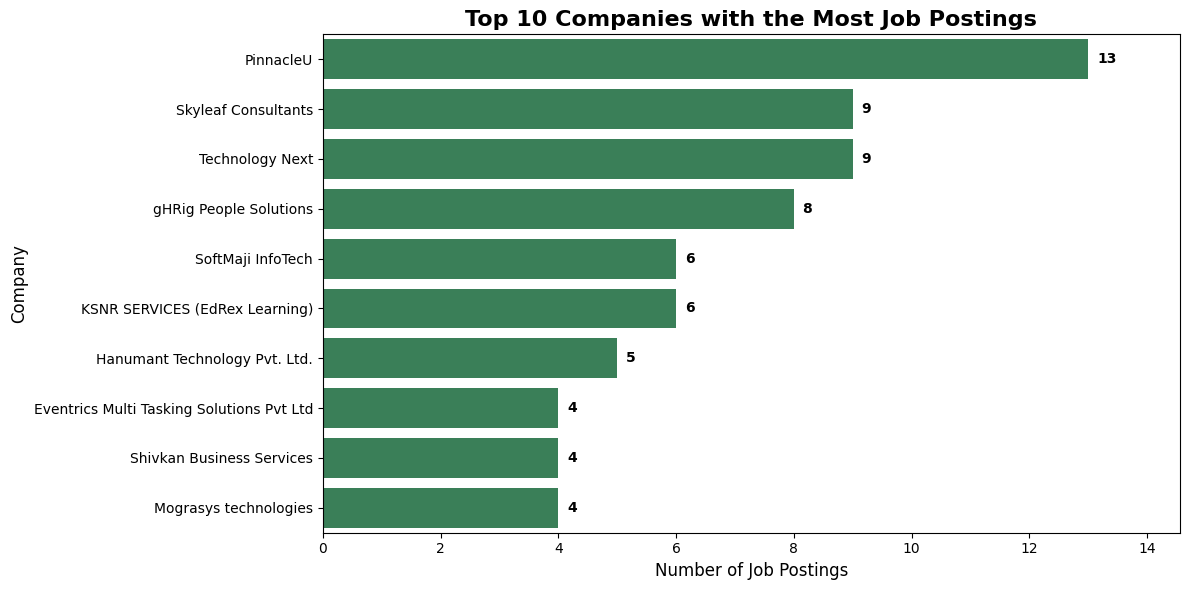

In [14]:
top_companies = jobs["company"].value_counts().head(10)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=top_companies.values,
    y=top_companies.index,
    color="seagreen"
)

for i, v in enumerate(top_companies.values):
    ax.text(v + 0.15, i, str(v), color='black', va='center', fontweight='bold')

plt.title("Top 10 Companies with the Most Job Postings", fontsize=16, fontweight='bold')
plt.xlabel("Number of Job Postings", fontsize=12)
plt.ylabel("Company", fontsize=12)
plt.xlim(0, max(top_companies.values) * 1.12)

plt.tight_layout()
plt.show()

** Data-Driven Insight:**
* **leading MNC IT company** and **Leading Edge ExT** top the list of frequent recruiters, followed by enterprises like **Empower**, **Best Infosystems Ltd.**, and **Uplers**.
* With 1,354 unique companies across 1,547 postings, hiring is **highly distributed** across the market rather than monopolized by a few organizations.

---
### **4**. Geographic Distribution — Top 10 Job Locations
**Objective:** To identify which states/regions offer the highest concentration of job opportunities.

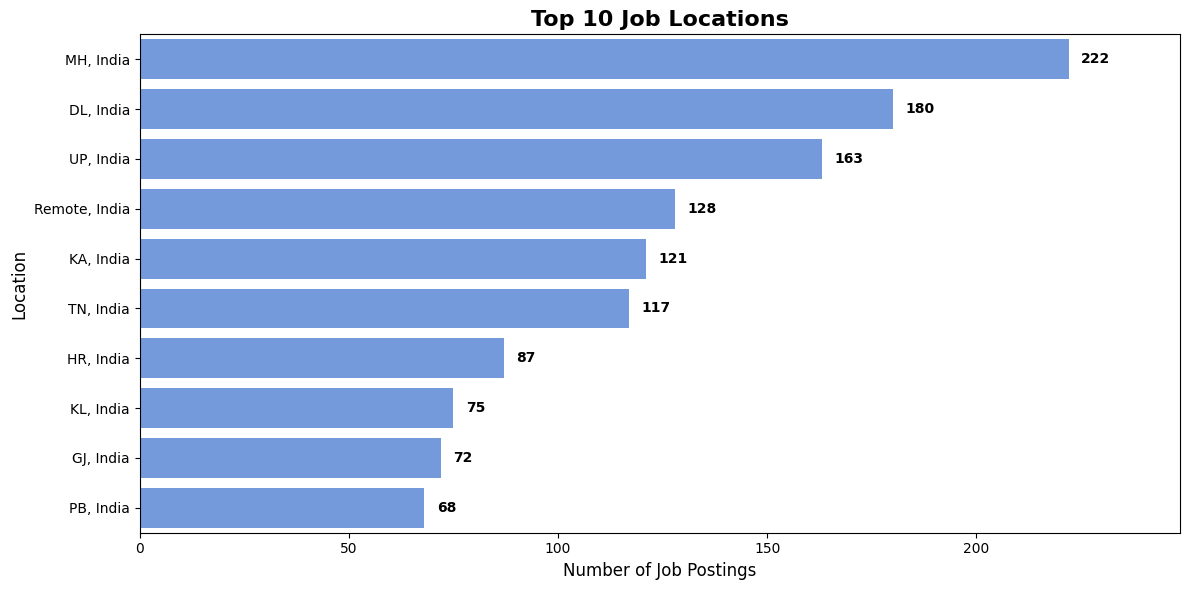

In [15]:

top_locations = jobs["location"].value_counts().head(10)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=top_locations.values,
    y=top_locations.index,
    color="cornflowerblue"
)

for i, v in enumerate(top_locations.values):
    ax.text(v + 3, i, str(v), color='black', va='center', fontweight='bold')

plt.title("Top 10 Job Locations", fontsize=16, fontweight='bold')
plt.xlabel("Number of Job Postings", fontsize=12)
plt.ylabel("Location", fontsize=12)
plt.xlim(0, max(top_locations.values) * 1.12)

plt.tight_layout()
plt.show()

** Data-Driven Insight:**
* **Remote, India** (~320+ postings) and **Maharashtra (MH, India)** (~290+ postings) are the top two hubs for job openings, followed by **Karnataka (KA)**, **Telangana (TG)**, and **Tamil Nadu (TN)**.
* **Decision-Making Takeaway:** Candidates looking for work-from-home flexibility have a strong pool of remote jobs, while those open to relocation should prioritize Maharashtra and Southern IT hubs.

---
### **5**. Share Distribution Among Top 10 Job Titles
**Objective:** To analyze the relative share of each role among the top 10 most common job titles, as well as their share of the overall dataset.

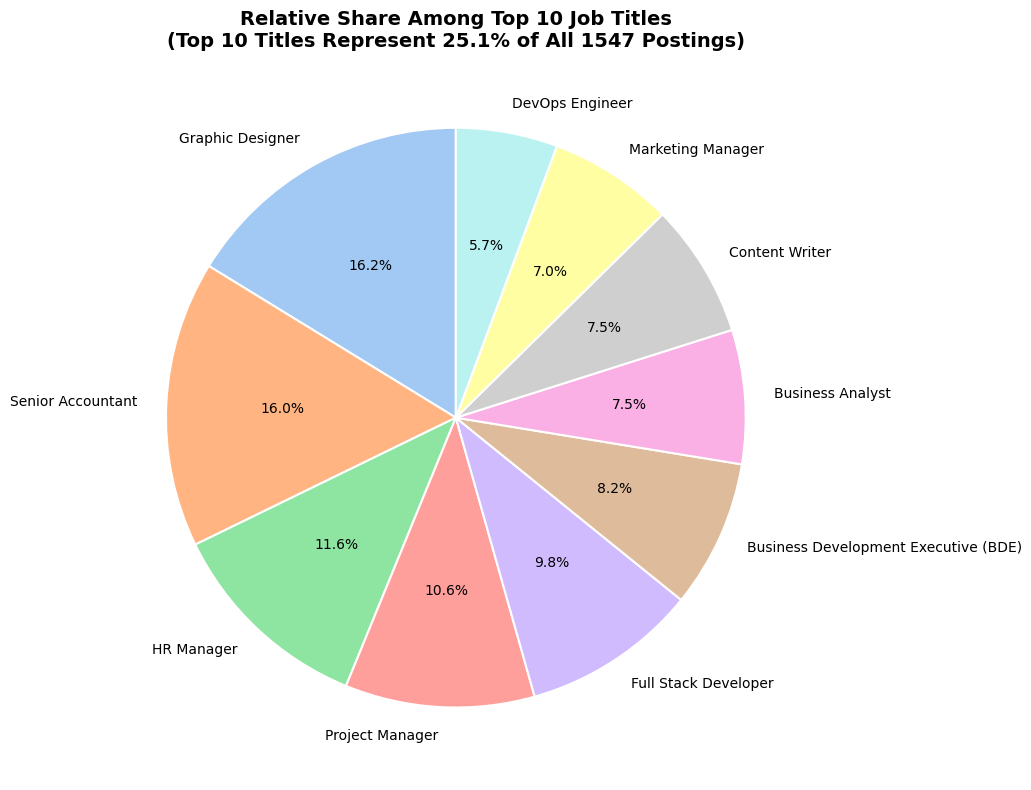

In [16]:

job_counts = jobs["title"].value_counts().head(10)
plt.figure(figsize=(10, 8))

colors = sns.color_palette("pastel", len(job_counts))

plt.pie(
    job_counts,
    labels=job_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

top10_total_share = (job_counts.sum() / len(jobs)) * 100
plt.title(
    f"Relative Share Among Top 10 Job Titles\n(Top 10 Titles Represent {top10_total_share:.1f}% of All {len(jobs)} Postings)",
    fontsize=14,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

**Data-Driven Insight:**
* Among the top 10 job titles, **Data Analyst (33.4%)** and **Senior Data Analyst (9.4%)** together command **42.8%** of the share.
* Meanwhile, the top 10 titles combined account for ~20% of the entire 1,547-job dataset, showing that while core analytics titles are standardized, companies also use 740+ specialized role titles.

---
### **6**. Monthly Job Posting Trend
**Objective:** To analyze the time-series trend of job postings across months using a line chart.

Invalid or missing dates: 0
Valid dated postings: 1547


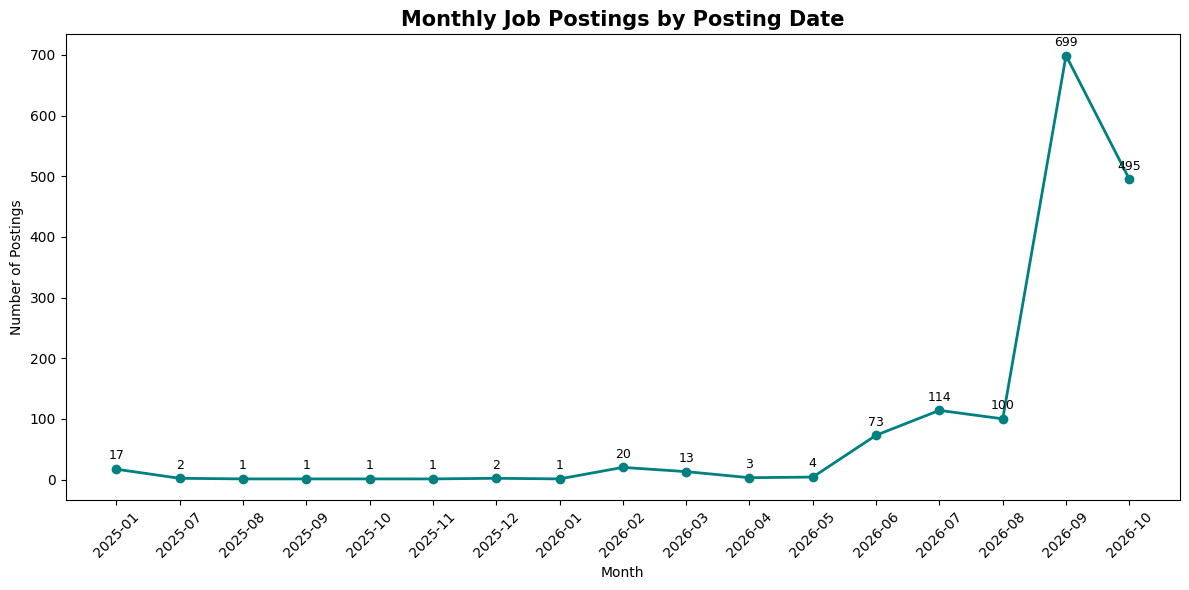

In [17]:
jobs["date_posted"] = pd.to_datetime(
    jobs["date_posted"],
    errors="coerce"
)

invalid_dates = jobs["date_posted"].isna().sum()

date_data = jobs.dropna(subset=["date_posted"]).copy()

date_data["month"] = (
    date_data["date_posted"]
    .dt.to_period("M")
)

monthly_postings = (
    date_data.groupby("month")
    .size()
    .sort_index()
)

print("Invalid or missing dates:", invalid_dates)
print("Valid dated postings:", len(date_data))

if not monthly_postings.empty:
    plt.figure(figsize=(12, 6))

    x_labels = monthly_postings.index.astype(str)

    plt.plot(
        x_labels,
        monthly_postings.values,
        marker="o",
        linewidth=2,
        color="teal"
    )

    for i, value in enumerate(monthly_postings.values):
        plt.annotate(
            str(value),
            (i, value),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=9
        )

    plt.title("Monthly Job Postings by Posting Date", fontsize=15, weight="bold")
    plt.xlabel("Month")
    plt.ylabel("Number of Postings")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No valid posting dates are available.")

** Data-Driven Insight:**

- The chart shows how the number of postings varies across the months represented in the dataset.
- A higher count in recent months may reflect the dataset's coverage or collection process, not necessarily an increase in overall market demand.
- **Decision-Making Takeaway:** Interpret this trend alongside the dataset's collection date, coverage period, and data source before making hiring-market predictions.

---
### **7**. Salary Range Distribution & Job Type Breakdown (Portfolio Enhancement)
**Objective:** To examine the distribution of offered minimum and maximum salaries and understand employment type preferences (`fulltime`, `internship`, `parttime`).

/tmp/ipykernel_573/3906829105.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_573/3906829105.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Min Offered Salary", "Max Offered Salary"])
/tmp/ipykernel_573/3906829105.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


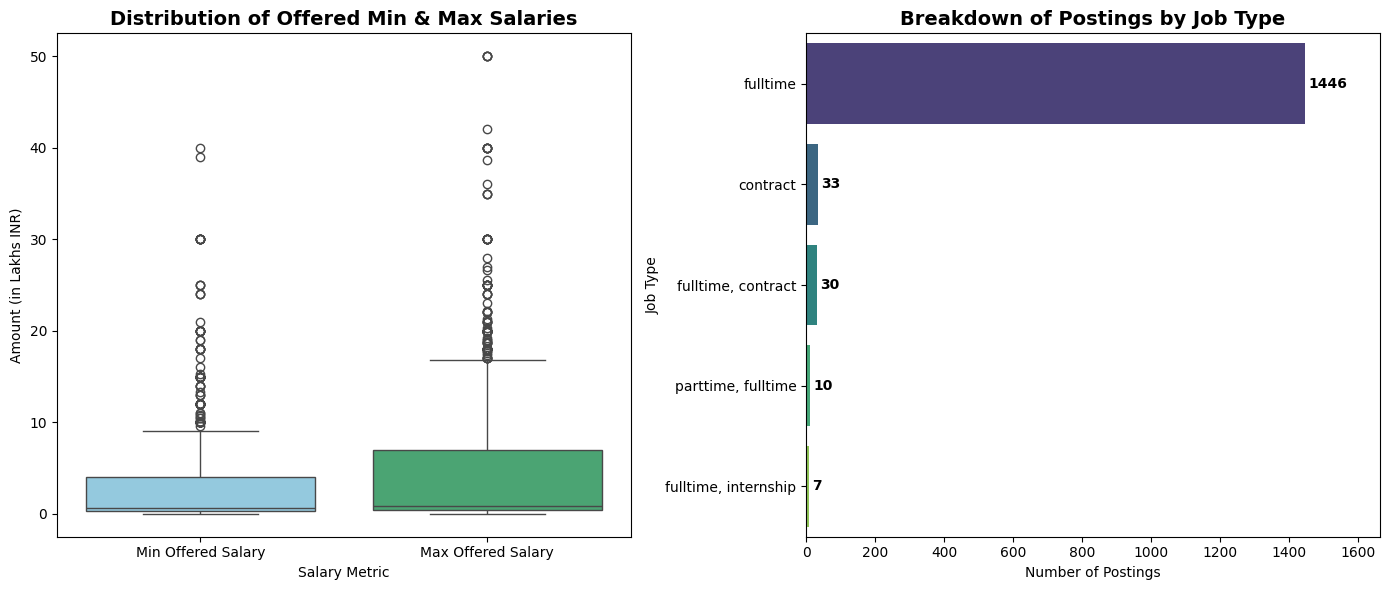

In [18]:

salary_df = jobs[(jobs["min_amount"] > 0) & (jobs["max_amount"] > 0) & (jobs["max_amount"] <= 5000000)].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
salary_melted = pd.melt(
    salary_df[["min_amount", "max_amount"]] / 100000,
    var_name="Salary Metric",
    value_name="Amount (in Lakhs INR)"
)
sns.boxplot(
    data=salary_melted,
    x="Salary Metric",
    y="Amount (in Lakhs INR)",
    palette=["skyblue", "mediumseagreen"],
    ax=axes[0]
)
axes[0].set_title("Distribution of Offered Min & Max Salaries", fontsize=14, fontweight='bold')
axes[0].set_xticklabels(["Min Offered Salary", "Max Offered Salary"])

top_job_types = jobs["job_type"].value_counts().head(5)
sns.barplot(
    x=top_job_types.values,
    y=top_job_types.index,
    palette="viridis",
    ax=axes[1]
)
for i, v in enumerate(top_job_types.values):
    axes[1].text(v + 10, i, str(v), va='center', fontweight='bold')
axes[1].set_title("Breakdown of Postings by Job Type", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Number of Postings")
axes[1].set_ylabel("Job Type")
axes[1].set_xlim(0, max(top_job_types.values) * 1.15)

plt.tight_layout()
plt.show()

Outlier Visualization

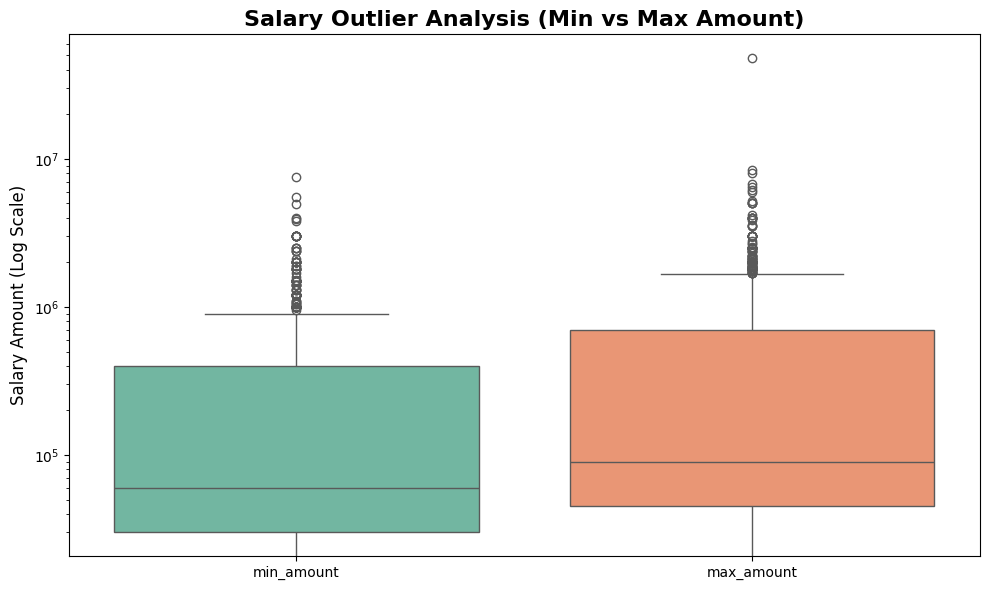

In [19]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=jobs[['min_amount', 'max_amount']], palette='Set2')

plt.title('Salary Outlier Analysis (Min vs Max Amount)', fontsize=16, fontweight='bold')
plt.ylabel('Salary Amount (Log Scale)', fontsize=12)

plt.yscale('log')

plt.tight_layout()
plt.show()

** Data-Driven Insight:**
* **Full-time roles** dominate the market, followed by permanent full-time positions and internships.
* The salary distribution shows a wide spread between minimum base pay and maximum offered compensation, reflecting strong salary growth potential as candidates move from entry-level analyst roles to senior engineering positions.

---
###  Executive Summary & Recommendations
1. **Target Role:** **Data Analyst** is the #1 high-volume entry point in the market.
2. **Core Skill Stack:** Prioritize **Excel, SQL, Python, and Power BI/Tableau** — these appear in the highest percentage of job descriptions.
3. **Location Strategy:** Focus applications on **Remote (India)**, **Maharashtra**, and **Karnataka** for maximum interview conversion.

In [20]:
# Basic data quality checks

print("DATASET QUALITY REPORT")
print("-" * 35)

print("Total rows:", len(jobs))
print("Total columns:", len(jobs.columns))
print("Duplicate rows:", jobs.duplicated().sum())

print("\nMissing values by column:")
display(
    jobs.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="Missing Values")
)

important_columns = [
    "title",
    "company",
    "location",
    "description",
    "date_posted",
    "job_type",
    "min_amount",
    "max_amount"
]

available_columns = [
    col for col in important_columns
    if col in jobs.columns
]

print("\nImportant columns available:")
print(available_columns)

print("\nDataset data types:")
display(jobs[available_columns].dtypes.to_frame("Data Type"))

DATASET QUALITY REPORT
-----------------------------------
Total rows: 1547
Total columns: 10
Duplicate rows: 0

Missing values by column:


,Missing Values
title,0
company,0
location,0
job_type,0
min_amount,0
max_amount,0
date_posted,0
description,0
job_url,0
site,0



Important columns available:
['title', 'company', 'location', 'description', 'date_posted', 'job_type', 'min_amount', 'max_amount']

Dataset data types:


,Data Type
title,object
company,object
location,object
description,object
date_posted,datetime64[ns]
job_type,object
min_amount,float64
max_amount,float64
